<div style="background: linear-gradient(120deg, #1a3a5c 0%, #2d6a9f 60%, #4a9eda 100%); padding: 28px 36px; border-radius: 14px; display: flex; align-items: center; gap: 28px; box-shadow: 0 4px 18px rgba(0,0,0,0.18);">
    <img src='Figures/iteso.jpg' style='height: 110px; border-radius: 8px; background: white; padding: 6px; flex-shrink: 0;'/>
    <div style='border-left: 2px solid rgba(255,255,255,0.4); padding-left: 28px;'>
        <h1 style='margin: 0 0 8px 0; color: white; font-size: 1.5em;'>Ingeniería y Ciencia de Datos</h1>
        <h3 style='margin: 0 0 8px 0; color: white; font-size: 1.5em;'>Laboratorio de Procesamiento de Datos</h3>
        <h3 style='margin: 0; color: rgba(255,255,255,0.8); font-weight: normal; font-size: 1.05em;'>Módulo 2: Estandarización y Normalización de datos</h3>
    </div>
</div>


La estandarización y la normalización cambian la escala de las variables numéricas para facilitar la comparación de sus valores

## 1. ¿Por qué cambiar la escala de los datos?

Imagina un reporte con **tiempo de entrega en minutos**, **importe en pesos** y **distancia en kilómetros**. Un cambio de 100 pesos y uno de 2 kilómetros no se pueden comparar por su tamaño numérico: tienen unidades y significados distintos. Incluso medir la misma distancia en metros hace que su número sea mil veces mayor, sin que el viaje cambie.

> Cambiar de escala es útil para:
- Comparar **posiciones relativas**: saber si un valor está cerca o lejos de lo habitual en su columna.
- Construir gráficas con un rango común cuando la pregunta lo requiere.
- Expresar medidas en una referencia consistente para comparar periodos o grupos.
- Evitar confundir un número grande con mayor importancia.

**No siempre es necesario.** Si queremos informar cuánto mide un pétalo, su longitud en centímetros es más interpretable que una puntuación transformada. Escalar no corrige errores, no elimina faltantes ni hace compatibles magnitudes distintas para sumarlas.


- **Normalización min–max:** expresa la posición dentro de un rango de referencia, habitualmente [0,1].
- **Estandarización z:** expresa la distancia a la media en unidades de desviación estándar.

> *Normalización* es una palabra ambigua: algunas fuentes la usan para min–max y otras para operaciones por fila. Aquí siempre indicaremos la fórmula. Ningún reescalamiento lineal garantiza que los datos se vuelvan normales.



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.datasets import load_wine, load_iris


In [2]:
def mostrar_transformacion(original, resultado, columna, titulo):
    display(pd.DataFrame({
        'Original': original[columna],
        'Transformado': resultado[columna],
    }).head(6).round(4))
    figura, ejes = plt.subplots(1, 2, figsize=(10, 3.5))
    for eje, serie, etiqueta in zip(ejes, [original[columna], resultado[columna]], ['Original', 'Transformado']):
        eje.hist(serie.dropna(), bins=12, color='#176b87', edgecolor='white')
        eje.set(title=etiqueta, xlabel=columna, ylabel='Observaciones')
    figura.suptitle(titulo)
    figura.tight_layout()
    plt.show()

In [3]:
wine = load_wine(as_frame=True)
vinos = wine.data.copy()
columnas = ['alcohol', 'color_intensity', 'proline']
datos = vinos[columnas].copy()

datos.head()


,alcohol,color_intensity,proline
0,14.23,5.64,1065.0
1,13.20,4.38,1050.0
2,13.16,5.68,1185.0
3,14.37,7.80,1480.0
4,13.24,4.32,735.0


In [4]:
datos.describe().T[['min', 'max', 'mean', 'std']].round(3)

,min,max,mean,std
alcohol,11.03,14.83,13.001,0.812
color_intensity,1.28,13.00,5.058,2.318
proline,278.00,1680.00,746.893,314.907


## 2. Normalización min–max: posición dentro de un rango

**Pregunta:** ¿dónde queda el largo de un pétalo entre el mínimo y el máximo observados?

$$x_{norm}=\frac{x-x_{min}}{x_{max}-x_{min}}$$

### Ejemplo numérico
Si el mínimo fuera 1 cm, el máximo 5 cm y un pétalo midiera 3 cm: $(3-1)/(5-1)=0.5$. Está a la mitad del **rango**, no necesariamente en la mediana ni en el percentil 50. Estos números son un ejemplo de cálculo; abajo usamos Iris real.

Cargamos Iris y aplicamos la fórmula por columna. Restar una Series a un DataFrame alinea cada parámetro con el nombre de su columna.

**Cómo leer el resultado:** en los datos utilizados como referencia, el menor valor será 0 y el mayor 1. Para obtener [0,100], multiplica el resultado por 100; para [a,b], usa $a+(b-a)x_{norm}$.

**Ventaja:** escala fácil de leer y útil para comparar posiciones dentro del rango de cada variable.

**Limitaciones:** depende de mínimos y máximos; un extremo puede comprimir al resto. Una observación nueva puede quedar fuera de [0,1]. Si máximo=mínimo, la fórmula no está definida.

**Pregunta breve:** si duplicamos todas las medidas en centímetros, ¿se modifica su posición min–max?

,Original,Transformado
0,1.4,0.0678
1,1.4,0.0678
2,1.3,0.0508
3,1.5,0.0847
4,1.4,0.0678
5,1.7,0.1186


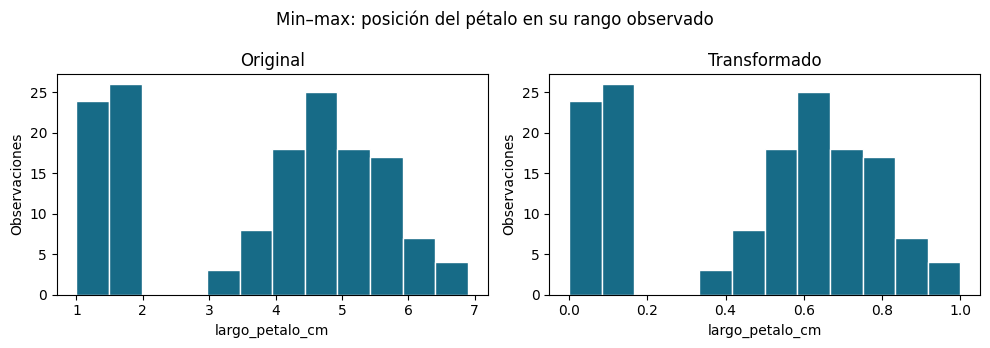

,min_transformado,max_transformado
largo_sepalo_cm,0.0,1.0
ancho_sepalo_cm,0.0,1.0
largo_petalo_cm,0.0,1.0
ancho_petalo_cm,0.0,1.0


In [5]:
iris = load_iris(as_frame=True)
flores = iris.data.rename(columns={
    'sepal length (cm)': 'largo_sepalo_cm',
    'sepal width (cm)': 'ancho_sepalo_cm',
    'petal length (cm)': 'largo_petalo_cm',
    'petal width (cm)': 'ancho_petalo_cm',
}).copy()

minimos_iris = flores.min()
rangos_iris = flores.max() - minimos_iris
flores_minmax = (flores - minimos_iris) / rangos_iris

mostrar_transformacion(flores, flores_minmax, 'largo_petalo_cm', 'Min–max: posición del pétalo en su rango observado')
pd.DataFrame({'min_transformado': flores_minmax.min(), 'max_transformado': flores_minmax.max()})


## 3. Estandarización z: distancia respecto a lo habitual

**Pregunta:** ¿el contenido de alcohol de un vino está cerca o lejos del promedio de estos vinos?

$$z=\frac{x-\bar{x}}{s}$$

### Ejemplo numérico con Wine
Para el primer vino, alcohol=14.23. La media es aproximadamente 13.00 y la desviación 0.81: $z\approx(14.23-13.00)/0.81\approx1.52$. Significa **1.52 desviaciones estándar por encima de la media**, no 152% ni 1.52 unidades originales.

Calculamos media y desviación de cada columna de Wine. Usaremos `std(ddof=0)` de forma consistente: divide entre $n$. El valor por defecto de pandas es `ddof=1`, que divide entre $n-1$. No hay que mezclar la convención de cálculo con la de comprobación.

**Interpretación:** z=0 corresponde a la media; z negativo significa estar por debajo, no que la medida original sea negativa. En la referencia utilizada, la media de z es 0 y su desviación es 1.

**Ventaja:** expresa diferencias en una unidad relativa común; permite comparar qué tan alejada del centro está cada medida.

**Limitaciones:** media y desviación son sensibles a extremos, el rango no es fijo y una columna constante tiene desviación cero. No convierte una distribución en normal ni autoriza interpretar z como una probabilidad sin supuestos adicionales.

**Pregunta breve:** ¿z=0 coincide siempre con la mediana?

,Original,Transformado
0,14.23,1.5186
1,13.20,0.2463
2,13.16,0.1969
3,14.37,1.6915
4,13.24,0.2957
5,14.20,1.4816


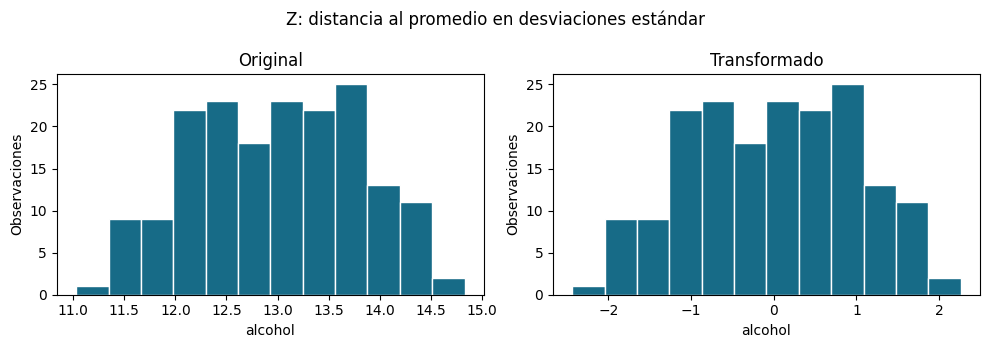

,media_z,std_z_ddof0
alcohol,-0.0,1.0
color_intensity,0.0,1.0
proline,-0.0,1.0


In [6]:
medias_wine = datos.mean()
std_wine = datos.std(ddof=0)
vinos_z = (datos - medias_wine) / std_wine

mostrar_transformacion(datos, vinos_z, 'alcohol', 'Z: distancia al promedio en desviaciones estándar')
pd.DataFrame({'media_z': vinos_z.mean(), 'std_z_ddof0': vinos_z.std(ddof=0)}).round(6)


In [7]:
print('Alcohol del primer vino:', datos.loc[0, 'alcohol'])
print('Z de ese mismo valor:', round(vinos_z.loc[0, 'alcohol'], 3))

recuperados = vinos_z * std_wine + medias_wine


Alcohol del primer vino: 14.23
Z de ese mismo valor: 1.519


In [8]:
from sklearn.preprocessing import StandardScaler

In [9]:
scaler = StandardScaler()

In [10]:
datos

,alcohol,color_intensity,proline
0,14.23,5.64,1065.0
1,13.20,4.38,1050.0
2,13.16,5.68,1185.0
3,14.37,7.80,1480.0
4,13.24,4.32,735.0
...,...,...,...
173,13.71,7.70,740.0
174,13.40,7.30,750.0
175,13.27,10.20,835.0
176,13.17,9.30,840.0


In [12]:
datos_escalados = scaler.fit_transform(datos)
datos_escalados

array([[ 1.51861254,  0.25171685,  1.01300893],
       [ 0.24628963, -0.29332133,  0.96524152],
       [ 0.19687903,  0.26901965,  1.39514818],
       [ 1.69154964,  1.18606801,  2.33457383],
       [ 0.29570023, -0.31927553, -0.03787401],
       [ 1.48155459,  0.73186953,  2.23903902],
       [ 1.71625494,  0.08301456,  1.72952002],
       [ 1.3086175 , -0.00349944,  1.74544249],
       [ 2.25977152,  0.06138606,  0.94931905],
       [ 1.0615645 ,  0.93517742,  0.94931905],
       [ 1.3580281 ,  0.29929955,  2.43010864],
       [ 1.38273339, -0.02512794,  1.69767508],
       [ 0.92568536,  0.23441405,  1.82505483],
       [ 2.16095032,  0.14790005,  1.28369089],
       [ 1.70390229,  1.05629702,  2.54793491],
       [ 0.77745356,  0.96978302,  1.79320989],
       [ 1.60508109,  0.49395604,  1.69767508],
       [ 1.02450655,  0.66698403,  1.22000102],
       [ 1.46920194,  1.575381  ,  2.97147258],
       [ 0.78980621,  0.01812906,  0.3124203 ],
       [ 1.3086175 ,  0.25604255,  0.105

In [13]:
scaler.inverse_transform(datos_escalados)

array([[1.423000e+01, 5.640000e+00, 1.065000e+03],
       [1.320000e+01, 4.380000e+00, 1.050000e+03],
       [1.316000e+01, 5.680000e+00, 1.185000e+03],
       [1.437000e+01, 7.800000e+00, 1.480000e+03],
       [1.324000e+01, 4.320000e+00, 7.350000e+02],
       [1.420000e+01, 6.750000e+00, 1.450000e+03],
       [1.439000e+01, 5.250000e+00, 1.290000e+03],
       [1.406000e+01, 5.050000e+00, 1.295000e+03],
       [1.483000e+01, 5.200000e+00, 1.045000e+03],
       [1.386000e+01, 7.220000e+00, 1.045000e+03],
       [1.410000e+01, 5.750000e+00, 1.510000e+03],
       [1.412000e+01, 5.000000e+00, 1.280000e+03],
       [1.375000e+01, 5.600000e+00, 1.320000e+03],
       [1.475000e+01, 5.400000e+00, 1.150000e+03],
       [1.438000e+01, 7.500000e+00, 1.547000e+03],
       [1.363000e+01, 7.300000e+00, 1.310000e+03],
       [1.430000e+01, 6.200000e+00, 1.280000e+03],
       [1.383000e+01, 6.600000e+00, 1.130000e+03],
       [1.419000e+01, 8.700000e+00, 1.680000e+03],
       [1.364000e+01, 5.100000e

#### cambiar la escala no cambia todo

En min–max y z hemos aplicado una transformación lineal con divisor positivo. Cambian las unidades del eje, pero se conserva el orden de las observaciones y la forma general de la distribución. Un histograma con nuevos números en el eje horizontal no demuestra que se haya alcanzado normalidad.

Hasta aquí hemos visto que:
- **Min–max:** posición respecto al mínimo y al máximo.
- **Z:** posición respecto a la media y la desviación.

Sin embargo, Los valores extremos pueden afectar esas referencias. 

## 4. Escalamiento robusto: mediana y rango intercuartílico

**Pregunta:** ¿cómo expresar posiciones relativas sin depender tanto de valores muy extremos?

$$r=\frac{x-\operatorname{mediana}(x)}{IQR},\qquad IQR=Q_3-Q_1$$

### Ejemplo numérico con Wine
Para prolina, mediana=673.5 e IQR=484.5. El primer vino tiene 1065: $(1065-673.5)/484.5\approx0.808$. Se encuentra **0.808 rangos intercuartílicos por encima de la mediana**.

`median()` calcula el centro y `quantile(0.75)-quantile(0.25)` la amplitud del 50% central. Se usan todos los vinos como referencia, sin borrar observaciones.

**Ventaja:** sus parámetros suelen cambiar menos que media y desviación al aparecer unos pocos extremos.

**Limitaciones:** no elimina atípicos ni los comprime automáticamente; el rango sigue abierto, la media no necesariamente queda en cero y no se puede dividir entre IQR=0. Robustez no significa inmunidad, especialmente en muestras pequeñas.

Después del ejemplo real añadiremos una prolina **artificial** de 30000 solo para comparar cómo cambian los parámetros; no pertenece al dataset original.

**Pregunta breve:** si el robusto de un valor es 20, ¿el método falló o el dato está lejos de la referencia central?

,Original,Transformado
0,1065.0,0.8080
1,1050.0,0.7771
2,1185.0,1.0557
3,1480.0,1.6646
4,735.0,0.1269
5,1450.0,1.6027


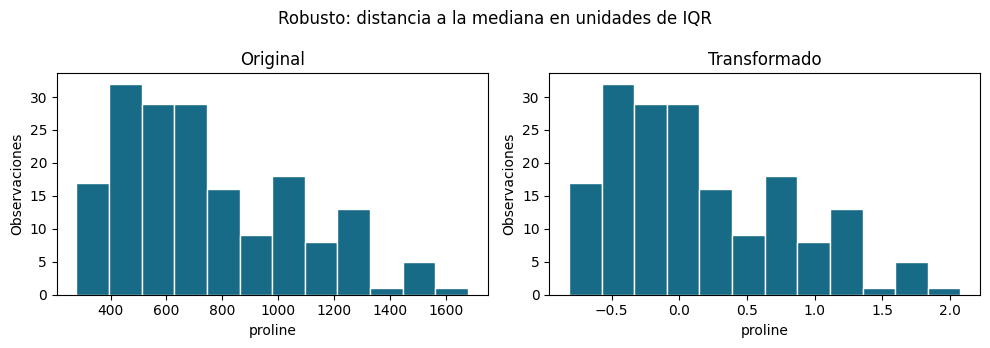

,mediana_transformada,IQR_transformado,std_transformada
alcohol,0.0,1.0,0.6156
color_intensity,0.0,1.0,0.7758
proline,0.0,1.0,0.6481


In [14]:
medianas_wine = datos.median()
iqr_wine = datos.quantile(0.75) - datos.quantile(0.25)
vinos_robusto = (datos - medianas_wine) / iqr_wine

mostrar_transformacion(datos, vinos_robusto, 'proline', 'Robusto: distancia a la mediana en unidades de IQR')
pd.DataFrame({
    'mediana_transformada': vinos_robusto.median(),
    'IQR_transformado': vinos_robusto.quantile(0.75) - vinos_robusto.quantile(0.25),
    'std_transformada': vinos_robusto.std(ddof=0),
}).round(4)

In [15]:
prolina_con_extremo = pd.concat([datos['proline'], pd.Series([30000.0], index=['artificial'])])
comparacion_parametros = pd.DataFrame({
    'Datos reales': [datos['proline'].mean(), datos['proline'].std(ddof=0), datos['proline'].median(), iqr_wine['proline']],
    'Con extremo artificial': [prolina_con_extremo.mean(), prolina_con_extremo.std(ddof=0), prolina_con_extremo.median(), prolina_con_extremo.quantile(0.75) - prolina_con_extremo.quantile(0.25)],
}, index=['Media', 'Desviación', 'Mediana', 'IQR'])
comparacion_parametros.round(3)

,Datos reales,Con extremo artificial
Media,746.893,910.318
Desviación,314.022,2202.736
Mediana,673.500,675.000
IQR,484.500,486.500


## 5. Máximo absoluto: conservar el cero y el signo

**Pregunta:** ¿cómo reducir la amplitud numérica sin restar un centro?

$$x_{abs}=\frac{x}{\max(|x|)}$$

### Ejemplo numérico
Para cambios de temperatura hipotéticos de [-6, 0, 3], el máximo absoluto es 6 y el resultado es [-1, 0, 0.5]. El cero sigue siendo cero y los negativos siguen siendo negativos.

Las longitudes de Iris son positivas. Dividiremos cada columna entre su propio máximo absoluto. Así el máximo queda en 1, pero **el mínimo no tiene por qué ser 0**: esta es la diferencia con min–max.

**Ventaja:** no desplaza el cero original y mantiene el signo. En datos con muchos ceros, no los convierte en otros valores por restar una media.

**Limitaciones:** depende de extremos, no centra en cero ni iguala desviaciones. El intervalo [-1,1] corresponde a la referencia usada; nuevas observaciones pueden excederlo. Una columna de puros ceros necesita una política explícita, porque su divisor es cero.

**Pregunta breve:** si todas las longitudes son positivas, ¿por qué sus mínimos transformados también pueden ser positivos?

,Original,Transformado
0,0.2,0.08
1,0.2,0.08
2,0.2,0.08
3,0.2,0.08
4,0.2,0.08
5,0.4,0.16


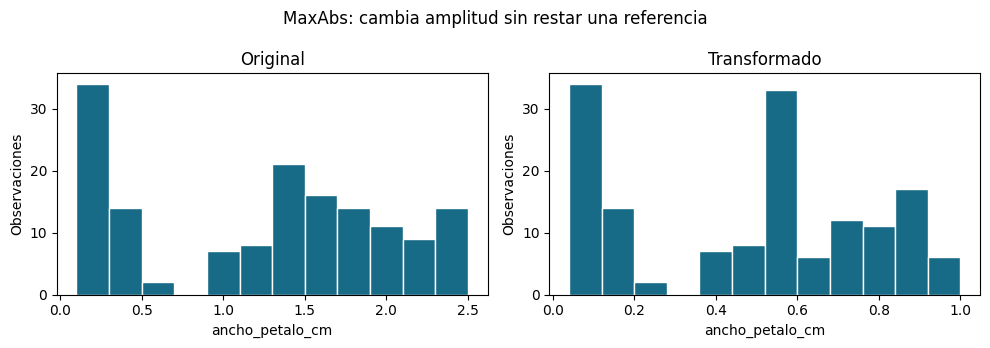

,min_transformado,max_abs_transformado
largo_sepalo_cm,0.5443,1.0
ancho_sepalo_cm,0.4545,1.0
largo_petalo_cm,0.1449,1.0
ancho_petalo_cm,0.0400,1.0


In [16]:
maximos_abs_iris = flores.abs().max()
flores_maxabs = flores / maximos_abs_iris

mostrar_transformacion(flores, flores_maxabs, 'ancho_petalo_cm', 'MaxAbs: cambia amplitud sin restar una referencia')
pd.DataFrame({
    'min_transformado': flores_maxabs.min(),
    'max_abs_transformado': flores_maxabs.abs().max(),
}).round(4)

In [17]:
cambios_hipoteticos = pd.Series([-6.0, 0.0, 3.0], name='cambio_temperatura')
cambios_maxabs = cambios_hipoteticos / cambios_hipoteticos.abs().max()
pd.DataFrame({'Cambio hipotético': cambios_hipoteticos, 'MaxAbs': cambios_maxabs})


,Cambio hipotético,MaxAbs
0,-6.0,-1.0
1,0.0,0.0
2,3.0,0.5


## 6. Escalamiento decimal: reducir órdenes de magnitud

**Pregunta:** ¿cómo llevar números grandes a magnitudes menores que 1 con una regla sencilla?

$$x_{dec}=\frac{x}{10^j},\qquad j\geq0\text{ es el menor entero que permite }\max(|x_{dec}|)<1$$

### Ejemplo numérico con Wine
La prolina máxima es 1680. Dividir entre 1000 deja 1.68, por lo que todavía no cumple la regla. Dividir entre 10000 deja 0.168; usaremos $j=4$. Un valor de 1065 se convierte en 0.1065.

La desigualdad es estricta en esta clase: un máximo de 100 debe dividirse entre 1000, no entre 100. Para una columna de ceros, elegimos j=0.

Para cada columna, aumentamos el exponente hasta que la magnitud máxima quede por debajo de 1. La fórmula será distinta entre columnas porque sus máximos pueden tener diferentes órdenes de magnitud.

**Ventaja:** procedimiento sencillo conserva orden, signos y cero. Es útil si interesa una convención explícita de potencias de diez.

**Limitaciones:** no centra ni iguala dispersiones, depende del mayor valor y puede cambiar bruscamente al cruzar una potencia de diez. La posición decimal de un número no indica su importancia.

**Pregunta breve:** ¿por qué un máximo 99 y uno 100 pueden exigir exponentes distintos?

,Original,Transformado
0,1065.0,0.1065
1,1050.0,0.1050
2,1185.0,0.1185
3,1480.0,0.1480
4,735.0,0.0735
5,1450.0,0.1450


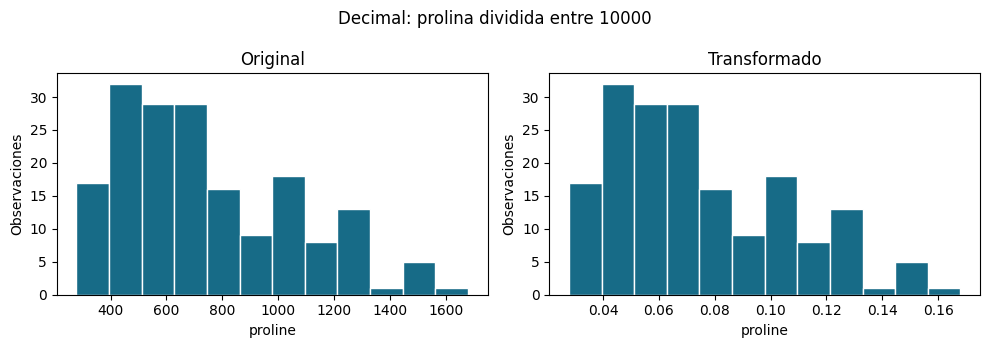

In [18]:
maximos_abs_wine = datos.abs().max()
exponentes = pd.Series(0, index=datos.columns, dtype=int)
for columna in datos.columns:
    while maximos_abs_wine[columna] / (10.0 ** exponentes[columna]) >= 1:
        exponentes[columna] += 1

divisores_decimales = 10.0 ** exponentes
vinos_decimal = datos / divisores_decimales

pd.DataFrame({
    'max_abs_original': maximos_abs_wine,
    'exponente_j': exponentes,
    'divisor': divisores_decimales,
    'max_abs_transformado': vinos_decimal.abs().max(),
})
mostrar_transformacion(datos, vinos_decimal, 'proline', 'Decimal: prolina dividida entre 10000')


## 7. Centrado: diferencias en la unidad original

**Pregunta:** ¿cuántos centímetros por encima o por debajo del promedio mide un pétalo?

$$x_c=x-\bar{x}$$

### Ejemplo numérico
Si el promedio de una medida fuera 4 cm y una flor midiera 5.5 cm, el valor centrado sería 1.5 cm. Es una **diferencia en centímetros**, no en desviaciones ni en una fracción del rango.

Restaremos la media de cada columna. La media queda en 0, pero la desviación se conserva. Centrar es parte del proceso de z, **no una estandarización completa**.

**Ventaja:** expresa diferencias fáciles de interpretar y conserva la unidad original.

**Limitaciones:** no iguala dispersiones, depende de la media y no acota el rango. No basta para comparar medidas con unidades distintas.

**Pregunta breve:** ¿qué operación le falta al centrado para obtener puntuación z?

,Original,Transformado
0,1.4,-2.358
1,1.4,-2.358
2,1.3,-2.458
3,1.5,-2.258
4,1.4,-2.358
5,1.7,-2.058


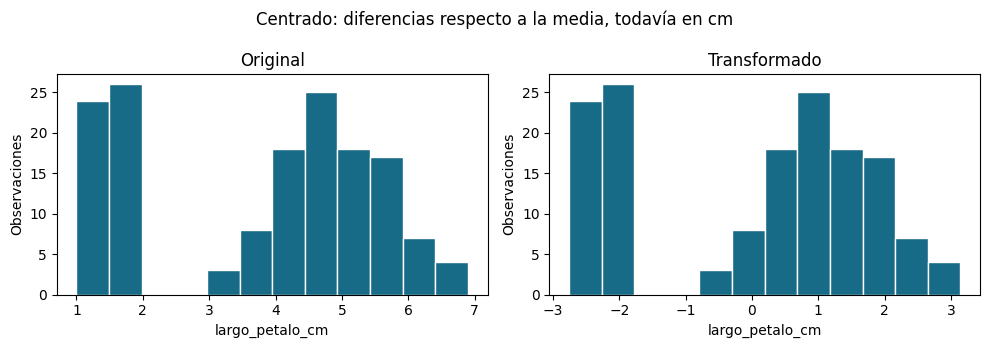

,media_original,media_centrada,std_original,std_centrada
largo_sepalo_cm,5.8433,-0.0,0.8253,0.8253
ancho_sepalo_cm,3.0573,-0.0,0.4344,0.4344
largo_petalo_cm,3.7580,-0.0,1.7594,1.7594
ancho_petalo_cm,1.1993,-0.0,0.7597,0.7597


In [19]:
medias_iris = flores.mean()
flores_centradas = flores - medias_iris

mostrar_transformacion(flores, flores_centradas, 'largo_petalo_cm', 'Centrado: diferencias respecto a la media, todavía en cm')
pd.DataFrame({
    'media_original': flores.mean(),
    'media_centrada': flores_centradas.mean(),
    'std_original': flores.std(ddof=0),
    'std_centrada': flores_centradas.std(ddof=0),
}).round(4)


## 8. ¿Cuál método elegir?

| Si la pregunta es… | Considera… | El resultado expresa… |
|---|---|---|
| ¿Dónde está el valor en el rango observado? | Min–max | Fracción del rango, no percentil |
| ¿Qué tan lejos está del promedio? | Z | Desviaciones estándar respecto a la media |
| ¿Qué tan lejos está del centro con menos influencia de extremos? | Robusto | IQR respecto a la mediana |
| ¿Cómo reducir amplitud manteniendo cero y signos? | MaxAbs | Fracción del máximo absoluto |
| ¿Cómo reducir órdenes de magnitud con una regla simple? | Decimal | Valor dividido entre una potencia de diez |
| ¿Cuánto difiere del promedio en su unidad original? | Centrado | Diferencia en la unidad original |

##### Elección según el algoritmo para un modelo de ML

No necesitamos estudiar estos algoritmos pero es importante comentar que la preparación de datos también depende del procedimiento que se usará después.

| Algoritmo o familia | ¿Conviene escalar? | Metodología inicial | ¿Por qué? |
|---|---|---|---|
| K vecinos más cercanos (KNN) | Sí, cuando usa distancias sensibles a la escala | Z, min–max si interesa un rango común | Una variable de gran magnitud puede dominar la distancia. La elección cambia qué diferencias se consideran grandes. |
| K-means y DBSCAN con distancia euclidiana | Generalmente sí | Z, robusto si hay extremos que afectan la referencia | Sus distancias dependen de la escala. En DBSCAN hay que elegir de nuevo el umbral de distancia después de transformar. Robusto no elimina atípicos ni vuelve robusto al algoritmo. |
| Máquinas de soporte vectorial (SVM), especialmente kernel RBF | Generalmente sí | Z, robusto cuando media y desviación son poco representativas | La escala afecta distancias, regularización y parámetros del kernel; estos se deben ajustar junto con el escalamiento. |
| Regresión lineal o logística con regularización (Ridge, Lasso, etc.) | Generalmente sí | Z | La penalización de los coeficientes depende de la escala de las variables. Sin regularización, escalar no garantiza mejores predicciones, aunque puede facilitar la optimización y la comparación de coeficientes. |
| Redes neuronales | Habitualmente sí | Z o min–max, según los datos y la arquitectura | Facilita la optimización numérica. No todas las redes requieren entradas en [0,1], min–max puede llevarse a [-1,1] si tiene sentido para la arquitectura. |
| PCA (reducción de dimensiones) | Depende de qué variación queremos representar | Z para dar una referencia de dispersión común, solo centrado si se desea conservar diferencias de varianza | PCA centra las variables, pero centrar no iguala escalas. Estandarizar cambia los componentes y no debe decidirse automáticamente si la varianza original es significativa. |
| Árbol de decisión, Random Forest y boosting basado en árboles (como XGBoost) | Normalmente no | Conservar las escalas originales | Los árboles convencionales separan mediante umbrales y dependen principalmente del orden de los valores. Z o min–max no suelen aportar una mejora por sí solos, esto no exime de revisar calidad y tipos de datos. |
| Naive Bayes | Depende de la variante | Gaussiano: normalmente no requiere escalar; multinomial: respetar conteos o pesos no negativos, Bernoulli: indicadores binarios | No aplicar z indiscriminadamente: genera negativos que no son válidos para la variante multinomial y no conserva la representación binaria. |

En scikit-learn, los equivalentes habituales son `StandardScaler`, `MinMaxScaler`, `RobustScaler` y `MaxAbsScaler`. 

**Conclusión:** elegir un método candidato según el algoritmo, el significado de las variables y sus distribuciones.

## Práctica de Laboratorio

1. **Completar una tabla.** Crea `resultado_practica` con cuatro columnas: `original_cm`, `minmax`, `z` y `robusto`. Aplica las tres fórmulas usando las 150 flores como referencia y `ddof=0`. Muestra solamente las primeras seis filas.

2. **Interpretar una flor.** Usa la fila con índice 0. Escribe **tres frases**, una por transformación: posición dentro del rango, distancia al promedio y distancia a la mediana. Indica la unidad relativa correcta. No basta decir 'es más grande'.

3.  **Recibir una observación nueva.** Supón que aparece una nueva medida de **5.0 cm**. Es un dato hipotético, no una flor adicional del dataset. Transfórmalo con los mismos parámetros del paso 1, **sin recalcularlos incluyendo el nuevo dato**. Responde: ¿min–max puede ser mayor que 1? ¿Qué nos dice eso sobre la referencia? ¿Cambiarías o recortarías el dato únicamente por ese resultado?

4. **Elegir cómo comunicar.** Un compañero quiere informar el tamaño del sépalo, otro quiere indicar qué tan lejos está del promedio. Elige qué columna mostrarías a cada uno y justifica en una oración por qué sus preguntas necesitan representaciones diferentes.


In [20]:
medida_practica = flores['ancho_sepalo_cm'].copy()
resultado_practica = pd.DataFrame({'original_cm': medida_practica})
nueva_medida_cm = 5.0

resultado_practica.head(6)

,original_cm
0,3.5
1,3.0
2,3.2
3,3.1
4,3.6
5,3.9


In [21]:
pd.Series({
    'mínimo de referencia': medida_practica.min(),
    'máximo de referencia': medida_practica.max(),
    'media de referencia': medida_practica.mean(),
    'std de referencia (ddof=0)': medida_practica.std(ddof=0),
    'mediana de referencia': medida_practica.median(),
    'IQR de referencia': medida_practica.quantile(0.75) - medida_practica.quantile(0.25),
}).round(4)

mínimo de referencia          2.0000
máximo de referencia          4.4000
media de referencia           3.0573
std de referencia (ddof=0)    0.4344
mediana de referencia         3.0000
IQR de referencia             0.5000
dtype: float64

In [22]:
rango_minmax = medida_practica.max() -  medida_practica.min()

In [23]:
iqr = medida_practica.quantile(0.75) - medida_practica.quantile(0.25)

In [25]:
#1.- Completar una tabla.. usando la columna ancho_sepalo_cm
resultado_practica = pd.DataFrame({'original_cm': medida_practica, 
                                   'minmax': (medida_practica - rango_minmax)/rango_minmax,
                                   'z': (medida_practica - medida_practica.mean())/medida_practica.std(ddof=0),
                                   'robusto': (medida_practica - medida_practica.median())/(iqr)})
resultado_practica.head(6)

,original_cm,minmax,z,robusto
0,3.5,0.458333,1.019004,1.0
1,3.0,0.250000,-0.131979,0.0
2,3.2,0.333333,0.328414,0.4
3,3.1,0.291667,0.098217,0.2
4,3.6,0.500000,1.249201,1.2
5,3.9,0.625000,1.939791,1.8


In [27]:
#2.- Interpretar una flor para ancho_sepalo_cm
medida_practica[0]

np.float64(3.5)

In [29]:
medida_practica.min(), medida_practica.max()

(np.float64(2.0), np.float64(4.4))

In [30]:
medida_practica.mean()

np.float64(3.0573333333333337)

In [31]:
medida_practica.std(ddof=0)

np.float64(0.4344109677354946)

In [32]:
# Con min max
rango_minmax

np.float64(2.4000000000000004)

In [33]:
(medida_practica[0] - medida_practica.min())/rango_minmax

np.float64(0.6249999999999999)

In [34]:
(medida_practica[0] - medida_practica.mean())/medida_practica.std(ddof=0)

np.float64(1.019004351971607)

In [35]:
(medida_practica[0] - medida_practica.median())/iqr

np.float64(1.0)

In [ ]:
# Con MinMax: Esta medida recorre el 62.5% del intervalo desde el mínimo de 2cm hasta el máximo de 4.4
# Con Z-Score (Estandarización): Está aproximadamente 1.019 desviaciones estandar por encima de la media (Estos no son centimetros)
# Robusto: La transformación nos da un valor de 1.0, esto quiere decir que este valor estpa a un rango interquantilico por encima de la mediana


In [36]:
#3.- Recibir una observación nueva.
nueva_medida_cm = 5.0